                 Model        MSE  R2 Score
0               Linear  18.102544  0.663311
1  Polynomial Degree 2  15.107354  0.719019
2  Polynomial Degree 3  14.943632  0.722064


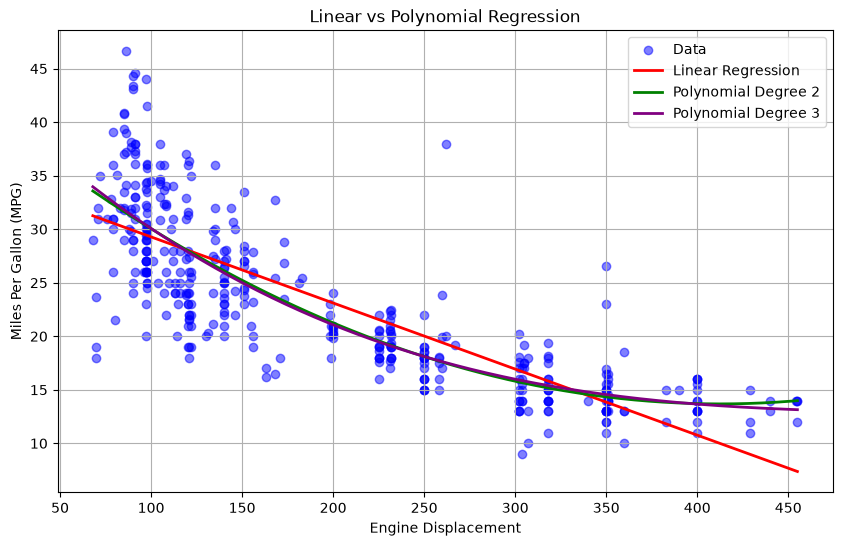

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.metrics import mean_squared_error, r2_score


url = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/mpg.csv"
df = pd.read_csv(url)

X = df[['displacement']]
y = df['mpg']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)


linear_model = LinearRegression()
linear_model.fit(X_train, y_train)
y_pred_linear = linear_model.predict(X_test)
mse_linear = mean_squared_error(y_test, y_pred_linear)
r2_linear = r2_score(y_test, y_pred_linear)


poly2 = PolynomialFeatures(degree=2)
X_train_poly2 = poly2.fit_transform(X_train)
X_test_poly2 = poly2.transform(X_test)

poly_model2 = LinearRegression()
poly_model2.fit(X_train_poly2, y_train)
y_pred_poly2 = poly_model2.predict(X_test_poly2)
mse2 = mean_squared_error(y_test, y_pred_poly2)
r22 = r2_score(y_test, y_pred_poly2)


poly3 = PolynomialFeatures(degree=3)
X_train_poly3 = poly3.fit_transform(X_train)
X_test_poly3 = poly3.transform(X_test)

poly_model3 = LinearRegression()
poly_model3.fit(X_train_poly3, y_train)
y_pred_poly3 = poly_model3.predict(X_test_poly3)
mse3 = mean_squared_error(y_test, y_pred_poly3)
r23 = r2_score(y_test, y_pred_poly3)


comparison = pd.DataFrame({
    'Model': ['Linear', 'Polynomial Degree 2', 'Polynomial Degree 3'],
    'MSE': [mse_linear, mse2, mse3],
    'R2 Score': [r2_linear, r22, r23]
})
print(comparison)

X_range = pd.DataFrame({
    'displacement': np.linspace(X['displacement'].min(), X['displacement'].max(), 300)
})

X_sorted = X.sort_values(by='displacement')
y_linear = linear_model.predict(X_sorted)

X_range_poly2 = poly2.transform(X_range)
y_poly2 = poly_model2.predict(X_range_poly2)

X_range_poly3 = poly3.transform(X_range)
y_poly3 = poly_model3.predict(X_range_poly3)

plt.figure(figsize=(10, 6))
plt.scatter(X['displacement'], y, color='blue', alpha=0.5, label='Data')
plt.plot(X_sorted['displacement'], y_linear, color='red', linewidth=2, label='Linear Regression')
plt.plot(X_range['displacement'], y_poly2, color='green', linewidth=2, label='Polynomial Degree 2')
plt.plot(X_range['displacement'], y_poly3, color='purple', linewidth=2, label='Polynomial Degree 3')

plt.xlabel("Engine Displacement")
plt.ylabel("Miles Per Gallon (MPG)")
plt.title("Linear vs Polynomial Regression")
plt.legend()
plt.grid(True)
plt.show()